In [1]:
import numpy as np pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
sns.set_theme(style="whitegrid")



In [2]:
df_clean = pd.read_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/data/processed/sms_dedup.csv")
df_clean.head()

,label,message,label_num,char_count,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20
1,ham,Ok lar... Joking wif u oni...,0,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28
3,ham,U dun say so early hor... U c already then say...,0,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13


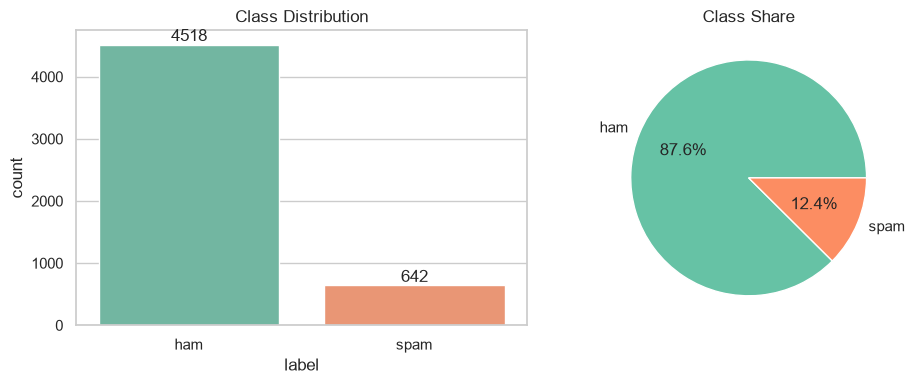

In [5]:
# class distribution
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

counts = df_clean["label"].value_counts()
sns.countplot(data=df_clean, x="label", order=counts.index, ax=ax[0], palette="Set2", legend = False, hue = "label")
ax[0].set_title("Class Distribution")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")

ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=sns.color_palette("Set2"))
ax[1].set_title("Class Share")
plt.tight_layout()
plt.show();

## Message length Analysis

In [6]:
df_clean["char_count"] = df_clean["message"].str.len()
df_clean["word_count"] = df_clean["message"].str.split().str.len()
df_clean["digit_count"] = df_clean["message"].str.count(r"\d")
df_clean["upper_ratio"] = df_clean["message"].apply(
    lambda x: sum(c.isupper() for c in x) / max(len(x), 1)
)
df_clean["has_url"] = df_clean["message"].str.contains(r"http|www\.", case=False, regex=True).astype(int)
df_clean["has_currency"] = df_clean["message"].str.contains(r"[£$€]", regex=True).astype(int)

df_clean.groupby("label")[["char_count", "word_count", "digit_count", "upper_ratio",
                           "has_url", "has_currency"]].mean().round(3)

,char_count,word_count,digit_count,upper_ratio,has_url,has_currency
label,,,,,,
ham,70.859,14.233,0.297,0.057,0.000,0.004
spam,137.414,23.699,15.442,0.110,0.139,0.333


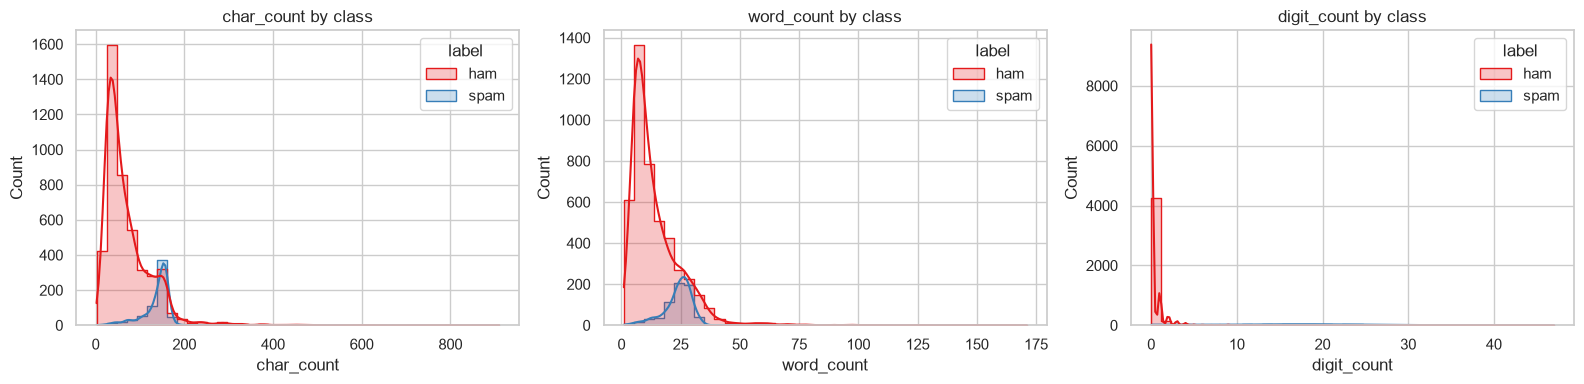

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for col, a in zip(["char_count", "word_count", "digit_count"], ax):
    sns.histplot(data=df_clean, x=col, hue="label", bins=40, kde=True, ax=a,
                 palette="Set1", element="step")
    a.set_title(f"{col} by class")
plt.tight_layout()
plt.show()

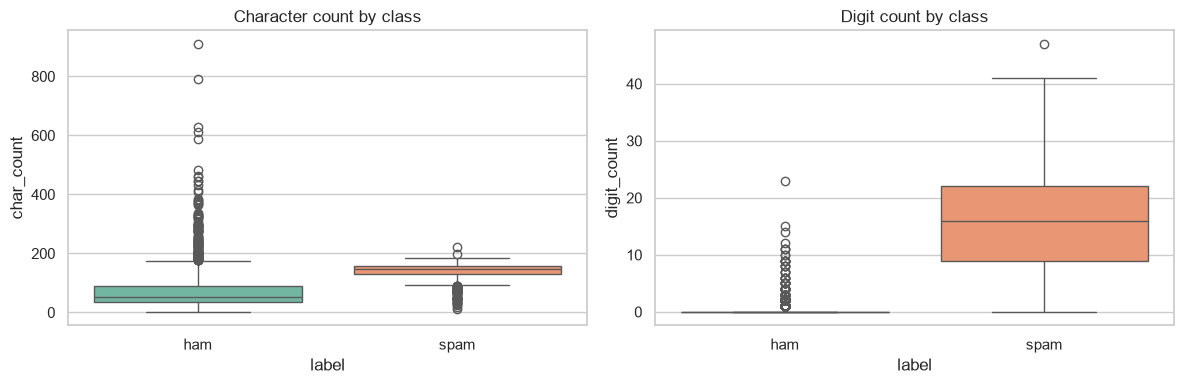

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_clean, x="label", y="char_count", ax=ax[0], palette="Set2",hue = "label", legend = False)
ax[0].set_title("Character count by class")
sns.boxplot(data=df_clean, x="label", y="digit_count", ax=ax[1], palette="Set2",hue = "label", legend = False)
ax[1].set_title("Digit count by class")
plt.tight_layout()
plt.show()

## Most common words per class

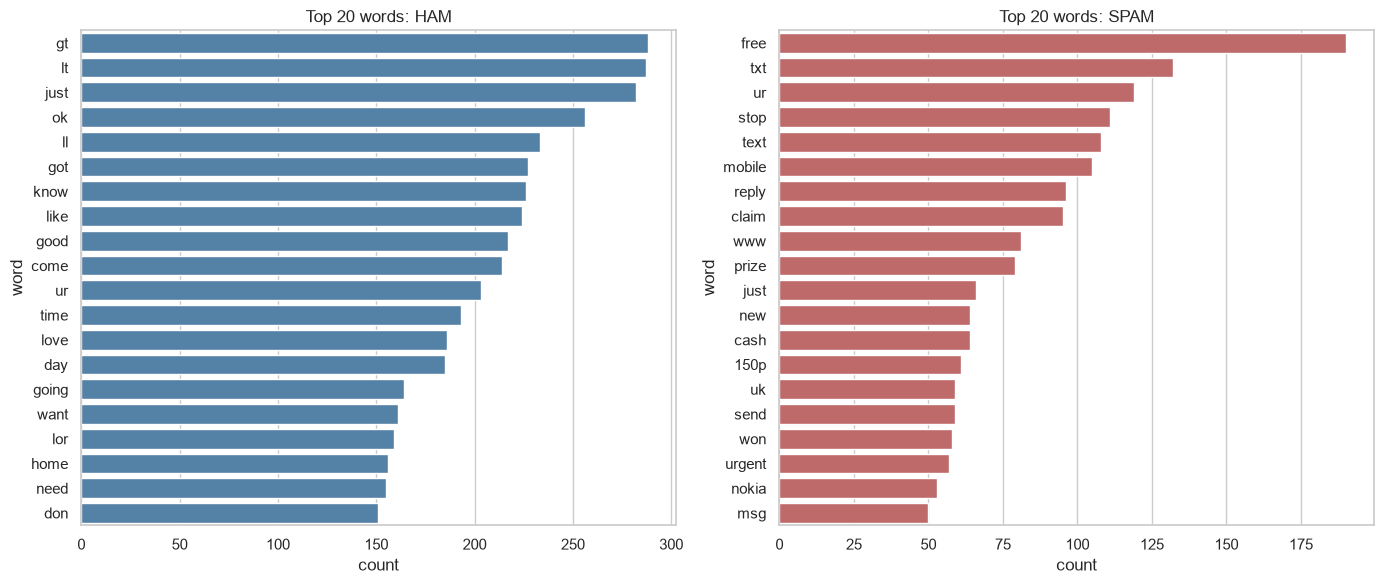

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

def top_words(texts, n=20):
    cv = CountVectorizer(stop_words="english", max_features=5000)
    X = cv.fit_transform(texts)
    freqs = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(cv.get_feature_names_out())
    idx = freqs.argsort()[::-1][:n]
    return pd.DataFrame({"word": vocab[idx], "count": freqs[idx]})

top_ham = top_words(df_clean.loc[df_clean["label"] == "ham", "message"])
top_spam = top_words(df_clean.loc[df_clean["label"] == "spam", "message"])

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_ham, y="word", x="count", ax=ax[0], color="steelblue")
ax[0].set_title("Top 20 words: HAM")
sns.barplot(data=top_spam, y="word", x="count", ax=ax[1], color="indianred")
ax[1].set_title("Top 20 words: SPAM")
plt.tight_layout()
plt.show()

## Word cloud

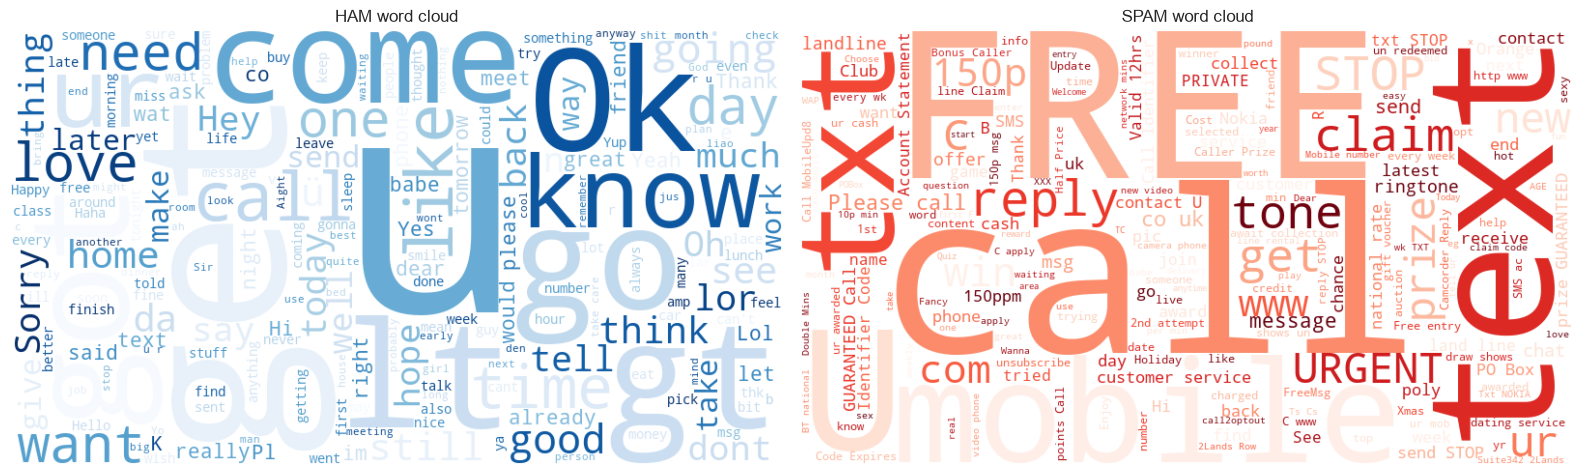

In [14]:
from wordcloud import WordCloud

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for label, a, cmap in zip(["ham", "spam"], ax, ["Blues", "Reds"]):
    text = " ".join(df_clean.loc[df_clean["label"] == label, "message"])
    wc = WordCloud(width=800, height=450, background_color="white",
                   stopwords=set(stopwords.words("english")), colormap=cmap).generate(text)
    a.imshow(wc, interpolation="bilinear")
    a.axis("off")
    a.set_title(f"{label.upper()} word cloud")
plt.tight_layout()
plt.show()